In [14]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC, LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score, precision_score, recall_score, classification_report

import matplotlib.pyplot as plt
import seaborn as sns
import pickle

In [15]:
import pandas as pd

# Load datasets
df_easy = pd.read_csv("../data/it_jobs_dataset.csv")
df_hard = pd.read_csv("../data/final_balanced_dataset.csv")

# Remove SOFTWARE_ENGINEER
df_easy = df_easy[df_easy["Category"] != "SOFTWARE_ENGINEER"]
df_hard = df_hard[df_hard["Category"] != "SOFTWARE_ENGINEER"]

# Optional: check
print("Easy dataset:")
print(df_easy["Category"].value_counts())

print("\nHard dataset:")
print(df_hard["Category"].value_counts())

Easy dataset:
Category
FRONTEND_DEVELOPER        200
BACKEND_DEVELOPER         200
FULL_STACK_DEVELOPER      200
AI_ML_ENGINEER            200
DATA_SCIENTIST            200
DATA_ANALYST              200
DEVOPS_ENGINEER           200
CLOUD_ENGINEER            200
MOBILE_APP_DEVELOPER      200
CYBERSECURITY_ENGINEER    200
QA_TEST_ENGINEER          200
Name: count, dtype: int64

Hard dataset:
Category
BACKEND_DEVELOPER         223
FULL_STACK_DEVELOPER      222
CYBERSECURITY_ENGINEER    217
FRONTEND_DEVELOPER        205
CLOUD_ENGINEER            201
DATA_ANALYST              200
DEVOPS_ENGINEER           198
AI_ML_ENGINEER            196
MOBILE_APP_DEVELOPER      191
QA_TEST_ENGINEER          182
DATA_SCIENTIST            180
Name: count, dtype: int64


In [16]:
# Sample (60-40)
df_easy_sample = df_easy.sample(frac=0.4, random_state=42)
df_hard_sample = df_hard.sample(frac=0.6, random_state=42)

# Merge
df = pd.concat([df_easy_sample, df_hard_sample])

# Shuffle
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

# Save
df.to_csv("../data/merged_dataset.csv", index=False)

print("Clean merged dataset ready!")

Clean merged dataset ready!


In [17]:
data = pd.read_csv("../data/merged_dataset.csv")

data.head()

,Category,Resume
0,FRONTEND_DEVELOPER,"Worked on projects using JavaScript, Next.js, ..."
1,CLOUD_ENGINEER,"Designed projects using S3, Cloud Security, Az..."
2,DATA_ANALYST,"Built projects using Data Cleaning, Reporting,..."
3,DATA_SCIENTIST,"Worked on projects using Statistics, Visualiza..."
4,MOBILE_APP_DEVELOPER,"Built projects using Android, API Integration,..."


In [18]:
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r'\b(project|worked|developed|using)\b', '', text)
    text = re.sub(r'[^a-z\s]', '', text)
    return text

data["Resume"] = data["Resume"].apply(clean_text)

In [19]:
data["Category"].value_counts()

Category
BACKEND_DEVELOPER         238
CYBERSECURITY_ENGINEER    223
FULL_STACK_DEVELOPER      219
CLOUD_ENGINEER            211
AI_ML_ENGINEER            197
FRONTEND_DEVELOPER        195
DATA_ANALYST              193
DEVOPS_ENGINEER           193
MOBILE_APP_DEVELOPER      182
QA_TEST_ENGINEER          180
DATA_SCIENTIST            178
Name: count, dtype: int64

In [20]:
X = data["Resume"]
y = data["Category"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,     
    random_state=42
)

In [21]:
vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=15000,
    ngram_range=(1,2),
    min_df=2,
    max_df=0.85,
    sublinear_tf=True   #
)

X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

In [22]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

models = {
    # "Logistic Regression": LogisticRegression(max_iter=2000, C=2),
    "Random Forest": RandomForestClassifier(n_estimators=200),
    "Linear SVC": LinearSVC(C=2, class_weight="balanced", max_iter=5000),   
    "Naive Bayes": MultinomialNB()
}

results = {}

best_model = None
best_accuracy = 0
best_model_name = ""

for name, model in models.items():

    model.fit(X_train_vec, y_train)

    predictions = model.predict(X_test_vec)

    # ✅ Metrics
    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(y_test, predictions, average='weighted')
    recall = recall_score(y_test, predictions, average='weighted')
    f1 = f1_score(y_test, predictions, average='weighted')

    results[name] = accuracy

    print("\n==============================")
    print(name)

    print("Accuracy :", round(accuracy * 100, 2), "%")
    print("Precision:", round(precision * 100, 2), "%")
    print("Recall   :", round(recall * 100, 2), "%")
    print("F1 Score :", round(f1 * 100, 2), "%")

    print("\nClassification Report:\n")
    print(classification_report(y_test, predictions))

    if accuracy > best_accuracy:
        best_accuracy = accuracy
        best_model = model
        best_model_name = name


print("\n==============================")
print("Best Model:", best_model_name)
print("Best Accuracy:", round(best_accuracy * 100, 2), "%")


Random Forest
Accuracy : 83.26 %
Precision: 83.76 %
Recall   : 83.26 %
F1 Score : 83.19 %

Classification Report:

                        precision    recall  f1-score   support

        AI_ML_ENGINEER       0.82      0.72      0.77        39
     BACKEND_DEVELOPER       0.82      0.75      0.78        48
        CLOUD_ENGINEER       0.69      0.86      0.77        42
CYBERSECURITY_ENGINEER       0.77      0.82      0.80        45
          DATA_ANALYST       0.80      0.90      0.84        39
        DATA_SCIENTIST       0.94      0.94      0.94        35
       DEVOPS_ENGINEER       0.83      0.90      0.86        39
    FRONTEND_DEVELOPER       0.94      0.87      0.91        39
  FULL_STACK_DEVELOPER       0.85      0.66      0.74        44
  MOBILE_APP_DEVELOPER       0.91      0.89      0.90        36
      QA_TEST_ENGINEER       0.87      0.92      0.89        36

              accuracy                           0.83       442
             macro avg       0.84      0.84      0

In [23]:
from sklearn.metrics import classification_report
import pandas as pd

report = classification_report(y_test, predictions, output_dict=True)

df_report = pd.DataFrame(report).transpose()

df_report = df_report.iloc[:-1, :-1]

df_report

,precision,recall,f1-score
AI_ML_ENGINEER,0.636364,0.717949,0.674699
BACKEND_DEVELOPER,0.750000,0.812500,0.780000
CLOUD_ENGINEER,0.790698,0.809524,0.800000
CYBERSECURITY_ENGINEER,1.000000,0.844444,0.915663
DATA_ANALYST,0.850000,0.871795,0.860759
DATA_SCIENTIST,1.000000,0.942857,0.970588
DEVOPS_ENGINEER,0.603448,0.897436,0.721649
FRONTEND_DEVELOPER,1.000000,0.846154,0.916667
FULL_STACK_DEVELOPER,0.828571,0.659091,0.734177
MOBILE_APP_DEVELOPER,0.941176,0.888889,0.914286


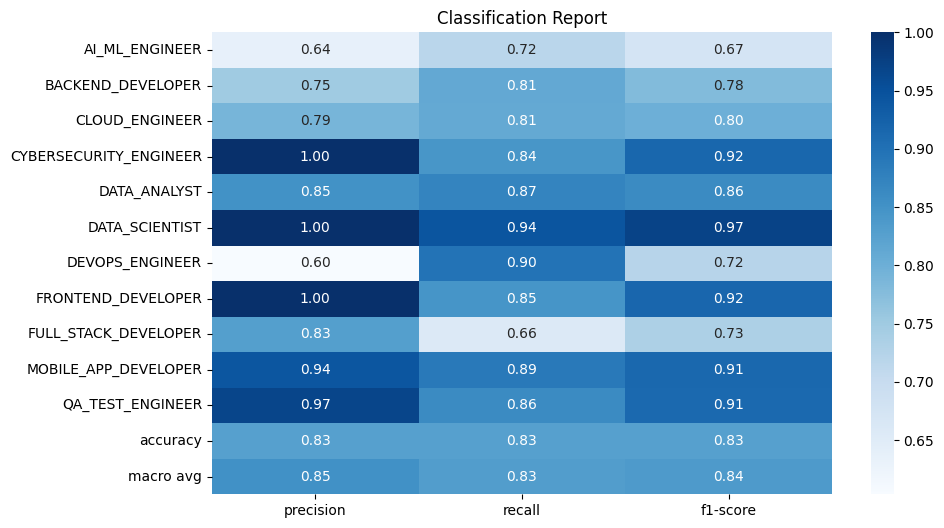

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

sns.heatmap(df_report, 
            annot=True, 
            cmap="Blues",
            fmt=".2f")

plt.title("Classification Report")
plt.show()

In [25]:
results

{'Random Forest': 0.832579185520362,
 'Linear SVC': 0.830316742081448,
 'Naive Bayes': 0.8280542986425339}

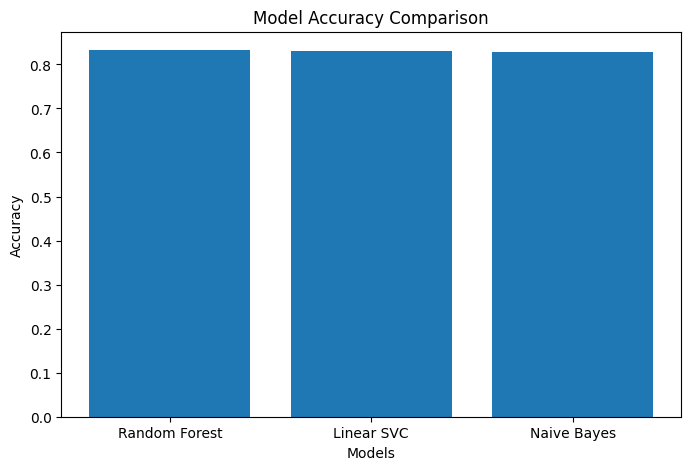

In [26]:
names = list(results.keys())
scores = list(results.values())

plt.figure(figsize=(8,5))
plt.bar(names, scores)
plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.xlabel("Models")
plt.show()

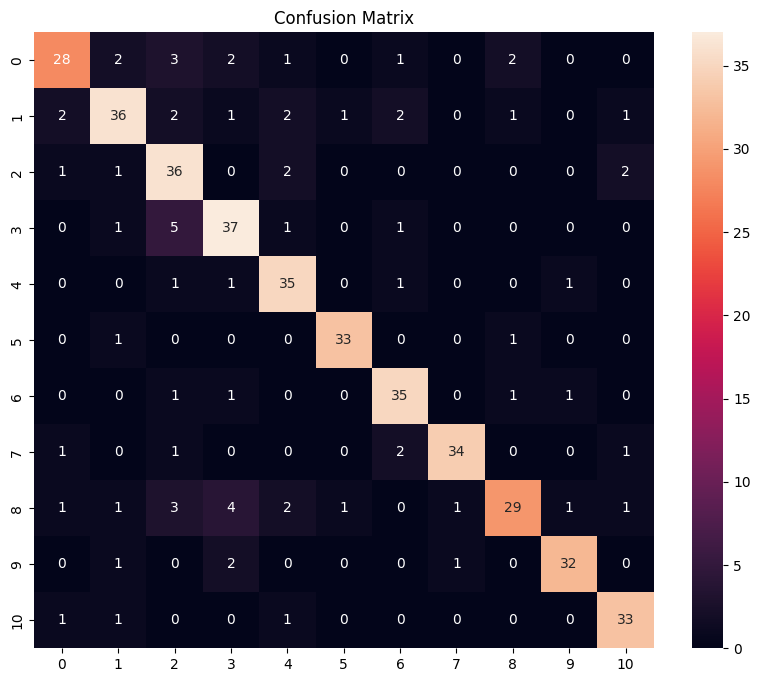

In [27]:
y_pred = best_model.predict(X_test_vec)

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10,8))
sns.heatmap(cm, annot=True, fmt="d")
plt.title("Confusion Matrix")
plt.show()

In [28]:
pickle.dump(best_model, open("../models/role_classifier.pkl", "wb"))
pickle.dump(vectorizer, open("../models/vectorizer.pkl", "wb"))

print("Best Model:", best_model_name)
print("Accuracy:", round(best_accuracy * 100, 2), "%")
print("Model saved successfully!")

Best Model: Random Forest
Accuracy: 83.26 %
Model saved successfully!
